# Chapter 6 — Building Your First Deep Neural Network: Introduction to Backpropagation

*Grokking Deep Learning* · Andrew W. Trask · book pp. 99–131

Until now every network had a single layer of weights. This chapter builds the first **deep** network (three layers, two weight matrices) and introduces the idea that makes deep learning trainable: **backpropagation**. Along the way the chapter reframes what a neural network is really doing: *searching for correlation*.

| # | Section | Core idea |
|---|---------|-----------|
| 1 | The streetlight problem | Learn a whole dataset, not one example |
| 2 | Matrices | Data as rows (examples) × columns (things recorded) |
| 3 | Building a network | From one example to the whole dataset |
| 4 | Stochastic / full / batch gradient descent | Three ways to learn from many examples |
| 5 | Networks learn correlation | Up/down "pressure" on each weight, plus the edge cases: overfitting, conflicting pressure, no correlation |
| 6 | Stacking networks + backpropagation | Create *intermediate* data that does correlate; pass delta backwards |
| 7 | Linear vs. nonlinear | Without a nonlinearity, extra layers add nothing |
| 8 | "Sometimes correlation" | Relu: switch a node off when it would be negative |
| 9 | Your first deep network | Forward pass + backprop in ~20 lines of NumPy |
| 10 | Why deep networks matter | Intermediate layers detect configurations of the input |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (6, 3.5)
plt.rcParams["axes.grid"] = True

---
## 1. The streetlight problem

You arrive at a street corner in a foreign country and the traffic light is unfamiliar. Which light combination means *walk*? You can't know directly, but you can sit and **record what each light pattern looks like and whether people walk or stop**. After a few observations, one pattern stands out: the middle light is perfectly correlated with people walking. That is exactly the kind of pattern we want a neural network to find on its own.

### Preparing the data
A supervised network needs two datasets: **what you know** (the light states) and **what you want to know** (walk or stop). The network learns to transform one into the other.

In [2]:
# columns: left light, middle light, right light      (1 = on, 0 = off)
streetlights = np.array([[1, 0, 1],
                         [0, 1, 1],
                         [0, 0, 1],
                         [1, 1, 1],
                         [0, 1, 1],
                         [1, 0, 1]])

walk_vs_stop = np.array([0, 1, 0, 1, 1, 0])      # 1 = WALK, 0 = STOP

for row, y in zip(streetlights, walk_vs_stop):
    print(f"left={row[0]} middle={row[1]} right={row[2]}  ->  {'WALK' if y else 'STOP'}")

left=1 middle=0 right=1  ->  STOP
left=0 middle=1 right=1  ->  WALK
left=0 middle=0 right=1  ->  STOP
left=1 middle=1 right=1  ->  WALK
left=0 middle=1 right=1  ->  WALK
left=1 middle=0 right=1  ->  STOP


---
## 2. Matrices and the matrix relationship

Math doesn't understand streetlights, but it understands **patterns of numbers**. Convention for data matrices:

* **one row per recorded example** (a moment in time);
* **one column per thing recorded** (here, one light).

A good data matrix mimics the real-world pattern. It doesn't have to be 0s and 1s: if the lights were on dimmers, the values could be fractions, or the same numbers multiplied by 10, or by 20. All of these are *scalar multiples* of each other and **express the same underlying pattern**. The pattern is a property of the matrices, not the matrices themselves.

In [3]:
# "Dimmer" versions of a streetlight dataset: same pattern, different scale
A_ = np.array([[.9, .0, 1], [.2, .8, 1], [.1, .0, 1], [.8, .9, 1], [.1, .7, 1], [.9, .1, 0]])
B_ = A_ * 10
C_ = B_ * 2
print("B == 10*A:", np.allclose(B_, A_ * 10), "| C == 2*B:", np.allclose(C_, B_ * 2))

# The output matrix is a *lossless representation* of the STOP/WALK notes:
# you can convert back and forth without losing anything (and 0/1 could be swapped too).
encoded = np.array([[0], [1], [0], [1], [1], [0]])
decoded = np.where(encoded.ravel() == 1, "WALK", "STOP")
print(decoded)

B == 10*A: True | C == 2*B: True
['STOP' 'WALK' 'STOP' 'WALK' 'WALK' 'STOP']


---
## 3. Building a neural network

First, the familiar single-example version. It learns *only* the first light pattern (`[1, 0, 1]` → STOP). Nothing here is new: dot product, error, delta, `weights -= alpha * input * delta`. NumPy lets us write that update as a single vector expression.

In [4]:
weights = np.array([0.5, 0.48, -0.7])
alpha = 0.1

x = streetlights[0]
goal = walk_vs_stop[0]

for it in range(20):
    pred  = x.dot(weights)
    error = (goal - pred) ** 2
    delta = pred - goal
    weights = weights - alpha * (x * delta)
    if it % 5 == 4:
        print(f"iter {it+1:2d}  error={error:.6f}  prediction={pred:.4f}")

iter  5  error=0.006711  prediction=-0.0819
iter 10  error=0.000721  prediction=-0.0268
iter 15  error=0.000077  prediction=-0.0088
iter 20  error=0.000008  prediction=-0.0029


### Learning the whole dataset (stochastic gradient descent)
To learn *all* the streetlights, loop over the examples inside each iteration and update the weights after **each one**. Over many passes the weights settle on values that work for every example.

error per pass (passes 1, 10, 20, 40): [2.656123, 0.055649, 0.009117, 0.000534]
final weights: [ 0.0139  1.0138 -0.016 ]


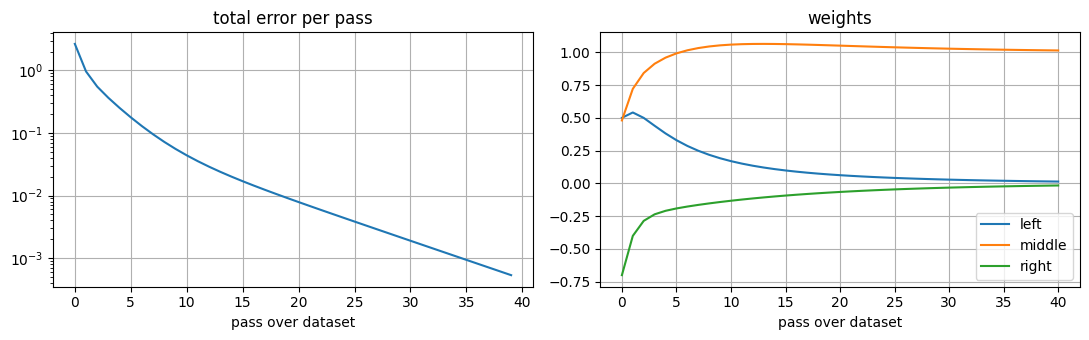

In [5]:
weights = np.array([0.5, 0.48, -0.7])
alpha = 0.1
total_err, w_hist = [], [weights.copy()]

for it in range(40):
    err_all = 0.0
    for i in range(len(walk_vs_stop)):
        x, goal = streetlights[i], walk_vs_stop[i]
        pred  = x.dot(weights)
        err_all += (goal - pred) ** 2
        delta = pred - goal
        weights = weights - alpha * (x * delta)
    total_err.append(err_all)
    w_hist.append(weights.copy())

w_hist = np.array(w_hist)
print("error per pass (passes 1, 10, 20, 40):", [round(float(total_err[i]), 6) for i in (0, 9, 19, 39)])
print("final weights:", weights)     # ≈ [0, 1, 0] -> only the middle light matters

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(total_err); ax[0].set(yscale="log", title="total error per pass", xlabel="pass over dataset")
for j, n in enumerate(["left", "middle", "right"]):
    ax[1].plot(w_hist[:, j], label=n)
ax[1].set(title="weights", xlabel="pass over dataset"); ax[1].legend()
plt.tight_layout(); plt.show()

---
## 4. Full, batch, and stochastic gradient descent

| Variant | When weights are updated | Notes |
|---------|-------------------------|-------|
| **Stochastic** (SGD) | after *every single example* | what we just did; noisy but makes many updates per pass |
| **Full** (average) gradient descent | once per pass, using the **average** `weight_delta` over the whole dataset | smooth, but only one update per pass |
| **Batch** gradient descent | after every `n` examples (the *batch size*, typically 8–256) | the usual compromise; the book returns to it later |

A compact comparison on the streetlight data (same `alpha`, same starting weights):

stochastic (batch=1)   final weights = [ 0.0034  1.0034 -0.0039]
batch (batch=2)        final weights = [ 0.034   1.0318 -0.0369]
full (batch=6)         final weights = [ 0.1899  1.0565 -0.138 ]


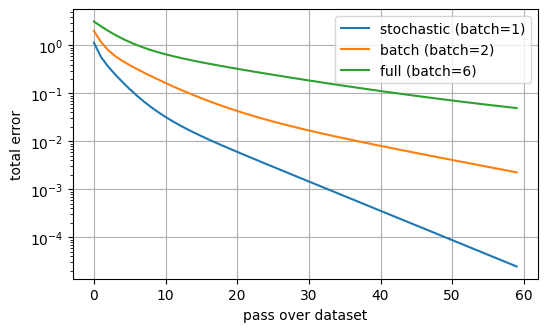

In [6]:
def train(batch_size, alpha=0.1, passes=60):
    w = np.array([0.5, 0.48, -0.7])
    errs = []
    for _ in range(passes):
        for s in range(0, len(streetlights), batch_size):
            X = streetlights[s:s + batch_size]
            y = walk_vs_stop[s:s + batch_size]
            delta = X.dot(w) - y
            w = w - alpha * X.T.dot(delta) / len(X)      # average weight_delta over the batch
        errs.append(((streetlights.dot(w) - walk_vs_stop) ** 2).sum())
    return w, errs

fig, ax = plt.subplots()
for name, bs in [("stochastic (batch=1)", 1), ("batch (batch=2)", 2), ("full (batch=6)", 6)]:
    w, e = train(bs)
    ax.plot(e, label=name)
    print(f"{name:22s} final weights = {w}")
ax.set(yscale="log", xlabel="pass over dataset", ylabel="total error"); ax.legend()
plt.show()

Per pass, SGD gets the most weight updates (6) and so descends fastest here; full gradient descent gets only one. All three end up in the same place. Their real trade-offs (smoothness, speed on hardware) matter later.

---
## 5. Neural networks learn correlation

The trained weights are ≈ `[0, 1, 0]`. From the network's point of view it never "knew" it was looking at streetlights. It just discovered **which input correlates with the output**: high weight where there's correlation, near-zero weight where there's none.

### Up and down pressure
How does the correlation get found? Each training example puts **upward pressure** (toward 1) or **downward pressure** (toward 0) on every weight whose input was on:

* if the goal is 1 and the input is on → `+` (that weight should grow);
* if the goal is 0 and the input is on → `−` (that weight should shrink);
* if the input is 0 → no pressure (the weight can't have caused any error).

Error is shared by all weights, so the real job is **error attribution**: figure out which weights contributed and leave the rest alone.

In [7]:
def pressure_table(inputs, goals):
    for row, g in zip(inputs, goals):
        marks = ["0" if v == 0 else ("+" if g == 1 else "−") for v in row]
        print("  ".join(str(v) for v in row), "  |  ", "  ".join(marks), "  ->  goal", g)

pressure_table(streetlights, walk_vs_stop)

1  0  1   |   −  0  −   ->  goal 0
0  1  1   |   0  +  +   ->  goal 1
0  0  1   |   0  0  −   ->  goal 0
1  1  1   |   +  +  +   ->  goal 1
0  1  1   |   0  +  +   ->  goal 1
1  0  1   |   −  0  −   ->  goal 0


Read down each column: the **left** weight gets two `−` and one `+` (→ 0); the **middle** weight gets only `+` (→ 1). The **right** weight is the interesting one. It gets three `+` and three `−`, a perfectly balanced tug of war.

> **Bottom line.** Each weight sees only its own input and the shared error. The prediction is a weighted sum; learning rewards inputs that correlate with the output by pushing their weights up, and punishes inputs that don't by pushing weights down. The result is a weighted sum that locks onto the correlation. "Pressure" isn't exact mathematics, but it's a very useful mental shortcut.

### Edge case: overfitting
Error is shared. If some combination of weights *accidentally* gives perfect predictions on one example, learning stops for that example. Take the first light `[1, 0, 1]` with weights `0.5` (left) and `−0.5` (right): the prediction is exactly 0, which is correct, yet those weights would be useless in the real world.

In [8]:
w_accident = np.array([0.5, 0.48, -0.5])
print("prediction for example 0:", streetlights[0].dot(w_accident), "(target 0 -> zero error!)")
print("predictions for all six :", streetlights.dot(w_accident))
print("targets                 :", walk_vs_stop)

prediction for example 0: 0.0 (target 0 -> zero error!)
predictions for all six : [ 0.   -0.02 -0.5   0.48 -0.02  0.  ]
targets                 : [0 1 0 1 1 0]


> **Deep learning's greatest weakness: overfitting.** Neural networks are so flexible that many weight settings fit a *subset* of the data perfectly without capturing the real pattern. More varied training examples are what knock the weights out of these accidental equilibria. The main challenge of deep learning is convincing the network to **generalize instead of memorize**. We will meet this again (chapter 8).

### Edge case: conflicting pressure
The right weight above has equal `+` and `−` pressure, yet it still ends up at ≈ 0. Why? The left and middle weights have enough signal to converge on their own and **absorb** most of the error. On the WALK examples the middle weight can take up whatever slack the right weight leaves, so those examples stop pushing on the right weight. On the STOP examples nothing else is switched on, so any non-zero right weight is pure error and keeps pushing it toward 0. In this dataset we got lucky because the middle input is so perfectly correlated; the chapter previews **regularization**, which would silence a weight with conflicting pressure straight away.

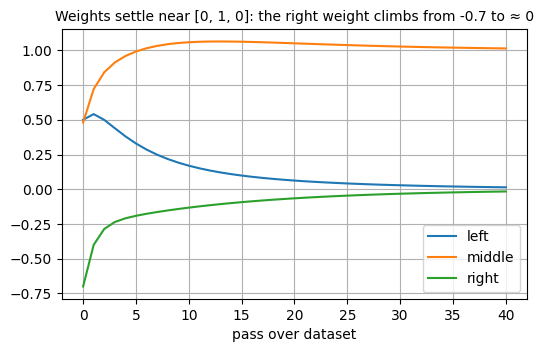

In [9]:
fig, ax = plt.subplots()
for j, n in enumerate(["left", "middle", "right"]):
    ax.plot(w_hist[:, j], label=n)
ax.set(title="Weights settle near [0, 1, 0]: the right weight climbs from -0.7 to ≈ 0", xlabel="pass over dataset")
ax.title.set_fontsize(10); ax.legend(); plt.show()

### Edge case: no correlation at all
Now a new dataset in which **no single input correlates with the output**. Every weight gets as much up pressure as down pressure:

In [10]:
S4 = np.array([[1, 0, 1],
               [0, 1, 1],
               [0, 0, 1],
               [1, 1, 1]])
Y4 = np.array([[1], [1], [0], [0]])

pressure_table(S4, Y4.ravel())

# The best any *single* weighted sum can do on this data (least squares):
w_best, *_ = np.linalg.lstsq(S4, Y4, rcond=None)
print("\nbest achievable total error with one layer of weights:", ((S4.dot(w_best) - Y4) ** 2).sum())

1  0  1   |   +  0  +   ->  goal 1
0  1  1   |   0  +  +   ->  goal 1
0  0  1   |   0  0  −   ->  goal 0
1  1  1   |   −  −  −   ->  goal 0

best achievable total error with one layer of weights: 1.0


No matter how long a one-layer network trains, it cannot get below an error of **1.0** on this data. The solution is the idea that defines deep learning.

---
## 6. Learning indirect correlation, stacking networks, and backpropagation

> If your data has no correlation, **create intermediate data that does.**

More precisely, networks search for correlation between their *input layer* and *output layer*. They don't know about "data". So stack two networks: the first (`layer_0 → layer_1`) produces an intermediate dataset, `layer_1`, that *does* correlate with the output, and the second (`layer_1 → layer_2`) uses that correlation to predict. It's still just a function made of weights, and gradient descent still applies.

```
layer_2   (1 node: walk/stop)
   ▲  weights_1_2   (4 × 1)
layer_1   (4 nodes: the intermediate dataset)
   ▲  weights_0_1   (3 × 4)
layer_0   (3 nodes: the streetlight)
```

Prediction is straightforward: the output of the lower network is the input of the upper one. **Learning** is the new part. The upper half (`layer_1 → layer_2`) is just like the networks from chapter 5. But what error measure do the *lower* weights use? What is the `delta` for `layer_1`?

### Backpropagation: long-distance error attribution
`layer_2` is a weighted sum of `layer_1`. If `layer_2` is too high by some amount, the `layer_1` nodes with **larger weights** contributed more, and nodes with a weight of 0 contributed nothing. So:

> `layer_1_delta = layer_2_delta × weights_1_2` (each weight acting as an amplifier running *backwards*)

This process of passing delta signals backward through the network is **backpropagation**. Once every layer has a delta, each weight matrix is updated exactly as before: input × output delta.

In [11]:
layer_2_delta = 0.25
weights_1_2 = np.array([0.0, 0.5, 1.0, -1.0])

layer_1_delta = layer_2_delta * weights_1_2
print("layer_1 deltas:", layer_1_delta)    # [0, 0.125, 0.25, -0.25]

layer_1 deltas: [ 0.     0.125  0.25  -0.25 ]


---
## 7. Linear vs. nonlinear

The author calls this *probably the hardest concept in the book*, so let's go slowly. As built so far, the three-layer network still **cannot** solve the new dataset, because:

> For any two consecutive weighted sums there is a *single* weighted sum with identical behaviour.

Two multiplications can always be replaced by one (`1 × 0.25 × 0.9 = 0.225` is the same as `1 × 0.225`). Stacking layers of plain weighted sums gives you nothing more than a more expensive single layer. Intuitively, each hidden node just "subscribes" to a fixed percentage of each input's movement, so the middle layer contributes no correlation of its own. It just remixes correlation that was already useless.

In [12]:
rng = np.random.default_rng(0)
W0 = rng.standard_normal((3, 4))
W1 = rng.standard_normal((4, 1))
W_collapsed = W0 @ W1                       # one (3 × 1) matrix

x = rng.standard_normal((5, 3))
print("two layers == one layer:", np.allclose(x @ W0 @ W1, x @ W_collapsed))

two layers == one layer: True


Let's confirm this empirically. We train (a) a one-layer net, (b) a three-layer net with **no nonlinearity**, on the "no correlation" dataset, then measure the total error with the final, fixed weights. Both are stuck at the theoretical floor of ≈ 1.0.

In [13]:
def total_error(predict):
    return ((predict(S4) - Y4) ** 2).sum()

# (a) one layer
np.random.seed(1)
w = 2 * np.random.random((3, 1)) - 1
for _ in range(2000):
    for i in range(4):
        x = S4[i:i+1]
        w -= 0.1 * x.T.dot(x.dot(w) - Y4[i:i+1])
err_one = total_error(lambda X: X.dot(w))

# (b) three layers, but linear (no relu)
np.random.seed(1)
w01 = 2 * np.random.random((3, 4)) - 1
w12 = 2 * np.random.random((4, 1)) - 1
for _ in range(2000):
    for i in range(4):
        l0 = S4[i:i+1]; l1 = l0.dot(w01); l2 = l1.dot(w12)
        d2 = l2 - Y4[i:i+1]
        d1 = d2.dot(w12.T)
        w12 -= 0.02 * l1.T.dot(d2)
        w01 -= 0.02 * l0.T.dot(d1)
err_lin3 = total_error(lambda X: X.dot(w01).dot(w12))

print(f"one-layer network           : total error = {err_one:.3f}")
print(f"three-layer, no nonlinearity: total error = {err_lin3:.3f}")

one-layer network           : total error = 1.031
three-layer, no nonlinearity: total error = 1.001


---
## 8. The secret to "sometimes correlation"

What we need is for a middle node to be correlated with an input **only sometimes**: "follow the left input, but *only when the right input is off*". The fix is almost embarrassingly simple:

> **If a node's value would be negative, set it to 0.**

When negative, the node is turned off and has *zero* correlation with anything; when positive it passes its value through. This gives each node a say of its own, conditional correlation, which a plain weighted sum can never provide. The "set negatives to 0" rule is a **nonlinearity**, specifically the function called **relu**. (There are many nonlinearities; relu is the simplest and often the best.)

In [14]:
def relu(x):
    return np.maximum(x, 0)           # same as the book's (x > 0) * x: x if x > 0, else 0

w_left, w_right = 1.0, -10.0           # "copy the left light, unless the right light is on"
print("left right | node value | after relu")
for l, r in [(1, 0), (1, 1), (0, 1), (0, 0)]:
    z = l * w_left + r * w_right
    print(f"  {l}     {r}   |   {z:6.1f}   |   {relu(z):4.1f}")

left right | node value | after relu
  1     0   |      1.0   |    1.0
  1     1   |     -9.0   |    0.0
  0     1   |    -10.0   |    0.0
  0     0   |      0.0   |    0.0


> **A note on how to study this.** The author pauses here to point out that you shouldn't hold every earlier lesson in your head at once. Once you trust a higher-level summary (*"networks search for correlation between input and output layers"*), you can set the granular details aside, just like an athlete doesn't consciously recite every lesson when swinging a bat.

---
## 9. Your first deep neural network

**Forward pass** (prediction). Two weight matrices connect three layers, initialised randomly between −1 and 1. The hidden layer goes through relu.

In [15]:
np.random.seed(1)

def relu(x):
    return np.maximum(x, 0)           # equivalent to the book's (x > 0) * x

streetlights = np.array([[1, 0, 1],
                         [0, 1, 1],
                         [0, 0, 1],
                         [1, 1, 1]])
walk_vs_stop = np.array([[1, 1, 0, 0]]).T

hidden_size = 4
weights_0_1 = 2 * np.random.random((3, hidden_size)) - 1
weights_1_2 = 2 * np.random.random((hidden_size, 1)) - 1

layer_0 = streetlights[0]
layer_1 = relu(np.dot(layer_0, weights_0_1))     # (3,) · (3,4) -> (4,)  then negatives -> 0
layer_2 = np.dot(layer_1, weights_1_2)           # (4,) · (4,1) -> (1,)
print("layer_0:", layer_0)
print("layer_1:", layer_1)
print("layer_2:", layer_2)

layer_0: [1 0 1]
layer_1: [0.     0.5183 0.     0.    ]
layer_2: [0.3919]


**Backward pass** (learning). The only new lines are the `layer_1_delta` computation and the relu derivative:

1. `layer_2_delta = layer_2 − goal` — same as always.
2. `layer_1_delta = layer_2_delta · weights_1_2ᵀ` — backpropagate through the weights.
3. Multiply by `relu2deriv(layer_1)`: it is `1` where the node was on and `0` where relu turned it off. A node that was off didn't contribute to the error, so its delta must be zero. (`relu2deriv` is simply the *slope* of relu.)
4. `weights -= alpha × (input layerᵀ · output layer's delta)`, for each weight matrix.

> The book's first listing uses `goal − prediction` for the delta and `+=` for the updates; the final listing uses `prediction − goal` with `-=`. They are equivalent. This notebook uses the latter throughout.

Error: 0.6342311598444467
Error: 0.3583840767631751
Error: 0.08301831133032973
Error: 0.006467054957103672
Error: 0.0003292669000750735
Error: 1.5055622665134864e-05


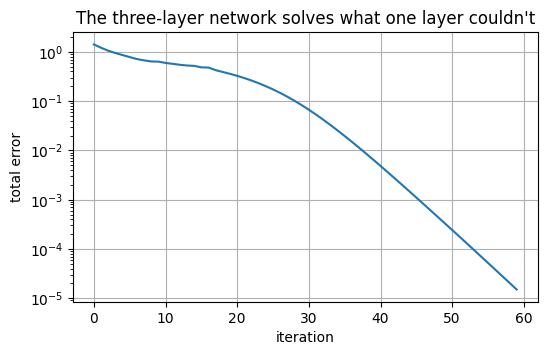

In [16]:
np.random.seed(1)

def relu(x):          return np.maximum(x, 0)      # same as (x > 0) * x
def relu2deriv(out):  return out > 0           # 1 where relu was "on", 0 where it was "off"

alpha = 0.2
hidden_size = 4
weights_0_1 = 2 * np.random.random((3, hidden_size)) - 1
weights_1_2 = 2 * np.random.random((hidden_size, 1)) - 1

history = []
for iteration in range(60):
    layer_2_error = 0
    for i in range(len(streetlights)):
        layer_0 = streetlights[i:i+1]
        layer_1 = relu(np.dot(layer_0, weights_0_1))
        layer_2 = np.dot(layer_1, weights_1_2)

        layer_2_error += np.sum((layer_2 - walk_vs_stop[i:i+1]) ** 2)

        layer_2_delta = layer_2 - walk_vs_stop[i:i+1]
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)

        weights_1_2 -= alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 -= alpha * layer_0.T.dot(layer_1_delta)

    history.append(layer_2_error)
    if iteration % 10 == 9:
        print("Error:", layer_2_error)

fig, ax = plt.subplots()
ax.plot(history); ax.set(yscale="log", xlabel="iteration", ylabel="total error", title="The three-layer network solves what one layer couldn't")
plt.show()

In [17]:
# Final predictions with the trained (fixed) weights
final = relu(streetlights.dot(weights_0_1)).dot(weights_1_2)
print("predictions:", final.ravel().round(3))
print("targets    :", walk_vs_stop.ravel())
print("total error with fixed weights:", ((final - walk_vs_stop) ** 2).sum().round(8))
print("\none-layer floor was 1.0 ->", f"deep network reaches {((final - walk_vs_stop) ** 2).sum():.2e}")

predictions: [1.    0.999 0.003 0.   ]
targets    : [1 1 0 0]
total error with fixed weights: 9.02e-06

one-layer floor was 1.0 -> deep network reaches 9.02e-06


### One iteration of backpropagation, step by step
The same code, unrolled for a single training example (with `hidden_size = 3`) so you can see each intermediate value. Note how the hidden nodes that relu switched off get a delta of exactly 0.

In [18]:
np.random.seed(1)
alpha, hidden_size = 0.2, 3
w01 = 2 * np.random.random((3, hidden_size)) - 1
w12 = 2 * np.random.random((hidden_size, 1)) - 1

l0 = streetlights[0:1]
pre = l0.dot(w01)                       # weighted sums before relu
l1  = relu(pre)
l2  = l1.dot(w12)
d2  = l2 - walk_vs_stop[0:1]

d1_raw = d2.dot(w12.T)                  # delta passed backwards through weights_1_2
mask   = relu2deriv(l1)                 # which hidden nodes were on
d1     = d1_raw * mask

print("layer_1 before relu :", pre)
print("layer_1 after relu  :", l1)
print("layer_2 (prediction):", l2, "  goal:", walk_vs_stop[0], "  layer_2_delta:", d2)
print("layer_1_delta (raw) :", d1_raw)
print("relu2deriv mask     :", mask.astype(int))
print("layer_1_delta       :", d1 + 0.0)      # (+ 0.0 only avoids printing -0.)

wd12 = l1.T.dot(d2)                     # (3,1)
wd01 = l0.T.dot(d1)                     # (3,3)
print("\nweight_delta_1_2:\n", wd12)
print("weight_delta_0_1:\n", wd01)

layer_1 before relu : [[-0.7934  0.1318 -1.2062]]
layer_1 after relu  : [[0.     0.1318 0.    ]]
layer_2 (prediction): [[-0.0213]]   goal: [1]   layer_2_delta: [[-1.0213]]
layer_1_delta (raw) : [[-0.0793  0.1651 -0.3783]]
relu2deriv mask     : [[0 1 0]]
layer_1_delta       : [[0.     0.1651 0.    ]]

weight_delta_1_2:
 [[ 0.    ]
 [-0.1346]
 [ 0.    ]]
weight_delta_0_1:
 [[0.     0.1651 0.    ]
 [0.     0.     0.    ]
 [0.     0.1651 0.    ]]


---
## 10. Why do deep networks matter?

Consider a dataset of photos labelled "cat" / "no cat". Just as in the second streetlight dataset, **no individual pixel correlates with whether there's a cat**. Only *configurations* of pixels do. A two-layer network can't build those configurations. A deeper one can:

* the first hidden layer's nodes learn to detect small configurations (an edge, a patch of fur, an eye);
* later layers combine those into larger ones (an ear, a face);
* the final layer finds the correlation between "many cat-like configurations are present" and "it's a cat".

> **This is the essence of deep learning:** creating intermediate layers (datasets), where each node represents the presence or absence of a different configuration of the inputs. Networks can have hundreds of layers, each node playing a part in detecting some configuration.

---
## Key takeaways

1. A neural network searches for **direct and indirect correlation** between its input and output layers. A hidden layer lets it *invent* correlation when none exists directly.
2. **Stochastic**, **full**, and **batch** gradient descent differ only in *when* weights are updated (after one example, after the whole dataset, or after `n` examples).
3. **Overfitting** is deep learning's greatest weakness: accidental weight configurations can give zero error without capturing the real pattern. More varied data and (later) regularization help.
4. **Backpropagation** = *multiply the output delta by the connecting weights* to get the previous layer's delta, then zero out nodes that relu switched off.
5. Without a **nonlinearity** (relu), stacked layers collapse into a single layer. Relu gives "sometimes correlation".

## Memorization challenge
As in chapter 5, the book says to move on only once you can write the three-layer network from memory:

```python
for iteration in range(60):
    for i in range(len(streetlights)):
        layer_0 = streetlights[i:i+1]
        layer_1 = relu(layer_0.dot(weights_0_1))
        layer_2 = layer_1.dot(weights_1_2)

        layer_2_delta = layer_2 - walk_vs_stop[i:i+1]
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)

        weights_1_2 -= alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 -= alpha * layer_0.T.dot(layer_1_delta)